# Simulación logística A013

Simulación determinista y API vectorizada por réplicas, con la previsión revisada de `demanda.ipynb`. El stock inicial es observado; las llegadas de enero y febrero son compromisos estimados.

**Convenciones.** Las llegadas entran al inicio del mes y las ventas se imputan tras 15 días. El stock inicial se reparte en edades 15, 45, 75, 105, 135, 165 y 210 días con unidades enteras. El stock de seguridad usa `sigma3_rel` como desviación relativa del **error acumulado durante el plazo de reposición**, de t+1 a t+3. Por tanto, `SS = z · sigma3_rel · suma(previsión de t+1 a t+3)`, sin otra raíz de tres. La API requiere previsión hasta `H+3` para cursar los últimos pedidos. Octubre–diciembre generan compromisos para A014 sin asignar un valor ficticio al stock final.

Los transfers son entrega directa al cliente en el mismo mes, con edad menor o igual a 90 días, y su disponibilidad es `floor(transfer_fraccion · déficit)`: es una sensibilidad explícita, no una disponibilidad infinita. Los aranceles y el cambio se imputan al coche vendido según su cohorte de nueva importación y se informa el importe que continúa en stock.

In [1]:
import numpy as np

SEGMENTOS = ["B", "C", "MD", "SSUV", "CSUV", "MSUV", "S"]
EDADES_INICIALES = np.array([210, 165, 135, 105, 75, 45, 15], dtype=float)
DIAS_MES = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

def _vector(x, nombre):
    x = np.asarray(x, dtype=float)
    if x.ndim == 0:
        x = np.full(7, x)
    if x.shape != (7,):
        raise ValueError(f"{nombre} debe ser escalar o tener siete segmentos")
    return x

def _ficha(datos):
    tabla = datos["segmentos"].set_index("segmento").reindex(SEGMENTOS)
    bruto = tabla["beneficio_bruto_marca_eur"].to_numpy(float)
    vm = tabla[["vm_real_0_90_eur", "vm_real_91_180_eur", "vm_real_mas_180_eur"]].to_numpy(float).T.copy()
    vm[2] = np.where(np.isnan(vm[2]), vm[1], vm[2])
    credito = tabla[["credito_dia_0_90_eur", "credito_dia_91_180_eur"]].fillna(0).to_numpy(float).T
    return bruto, vm, credito, tabla["prima_co2_eur"].to_numpy(float)

def _stock_inicial(datos):
    stock = datos["stock"]
    fila = stock.loc[stock["t"] == stock["t"].max()].set_index("segmento").reindex(SEGMENTOS)
    grupos = fila[["s_0_90", "s_91_180", "s_mas_180"]].fillna(0).to_numpy(int).T
    salida = np.zeros((7, 7), dtype=int)
    for inicio, destino, cantidad, n in [(0, 0, grupos[2], 1), (1, 3, grupos[1], 3), (4, 6, grupos[0], 3)]:
        # Las edades están de mayor a menor; el resto queda en las cohortes más antiguas.
        if n == 1:
            salida[0] += cantidad
        else:
            q, r = np.divmod(cantidad, n)
            salida[inicio:destino + 1] += q
            salida[inicio:inicio + 1] += r
    return salida

def _compromisos(datos, meses_pipeline, multiplicador):
    stock = datos["stock"]
    ultimo = stock["t"].max()
    reciente = stock.loc[stock["t"] > ultimo - meses_pipeline]
    tabla = reciente.pivot(index="t", columns="segmento", values="wholesale").reindex(columns=SEGMENTOS)
    medias = []
    for segmento in SEGMENTOS:
        serie = tabla[segmento].dropna()
        activa = serie.loc[serie.cumsum() > 0]
        medias.append(0 if activa.empty else int(np.rint(activa.mean() * multiplicador)))
    return np.asarray(medias, dtype=int)

def extender_demanda(prevision, datos, meses=21):
    """Continuidad A014: perfil A009–A010 y nivel desestacionalizado del cierre A013."""
    prevision = np.asarray(prevision, dtype=float)
    if prevision.shape != (12, 7) or meses < 12:
        raise ValueError("Se necesitan doce meses por siete segmentos y horizonte >= 12")
    mercado = datos["mercado"].groupby(["anio", "mes", "segmento"])["unidades"].sum()
    perfiles = []
    for anio in ["A009", "A010"]:
        anual = mercado.loc[anio].unstack("segmento").reindex(columns=SEGMENTOS).to_numpy(float)
        perfiles.append(anual / anual.mean(axis=0))
    perfil = np.mean(perfiles, axis=0)
    nivel = (prevision[9:12] / perfil[9:12]).mean(axis=0)
    futuro = np.asarray([perfil[i % 12] * nivel for i in range(meses - 12)]).reshape(-1, 7)
    return np.vstack([prevision, futuro])

def crear_plan(demanda_plan, datos, sigma3_rel, z=1.28, meses_pipeline=6, multiplicador_pipeline=1., frenar_no_rentables=False):
    """Crea llegadas H×7 enteras; enero y febrero son compromisos de wholesale."""
    demanda = np.asarray(demanda_plan, dtype=float)
    if demanda.ndim != 2 or demanda.shape[1] != 7:
        raise ValueError("demanda_plan debe tener forma H×7 en el orden SEGMENTOS")
    h = len(demanda)
    sigma3_rel, z = _vector(sigma3_rel, "sigma3_rel"), _vector(z, "z")
    bruto, vm, _, _ = _ficha(datos)
    plan = np.zeros((h, 7), dtype=int)
    plan[:min(2, h)] = _compromisos(datos, meses_pipeline, multiplicador_pipeline)
    disponible = _stock_inicial(datos).sum(axis=0).astype(float)
    for mes in range(h):
        objetivo = demanda[max(0, mes - 2):mes + 1].sum(axis=0)
        ss = z * sigma3_rel * objetivo
        if mes >= 2:
            pedido = np.ceil(np.maximum(0, demanda[mes] + ss - disponible)).astype(int)
            if frenar_no_rentables:
                # Sin escenario económico conocido, la contribución marginal central
                # descuenta VM joven y 30 €/coche de coste de stock, no la prima CO₂.
                pedido[bruto - vm[0] - 30 < 0] = 0
            plan[mes] = pedido
        disponible = np.maximum(0, disponible + plan[mes] - demanda[mes])
    return plan

def simular_politica(demanda_real, demanda_plan, datos, sigma3_rel, z=1.28, plan_inicial=None, parametros=None):
    """Simula R réplicas, H meses y siete segmentos con revisión solo a m+3.

parametros admite: prima_co2 (False), arancel_eur (0×7), cambio_eur (0×7),
suministro ((segmento, mes_produccion_1based) o None), transfer_fraccion (0),
edad_desplazamiento (0), vm_csuv_mayor_factor (1), frenar_no_rentables (False)
y peso_revision (0.5). Los dos primeros incrementos solo gravan nuevas llegadas.
"""
    p = {} if parametros is None else dict(parametros)
    real = np.asarray(demanda_real, dtype=int)
    previsto = np.asarray(demanda_plan, dtype=float)
    if real.ndim != 3 or real.shape[2] != 7 or previsto.ndim != 2 or previsto.shape[1] != 7:
        raise ValueError("demanda_real es R×H×7 y demanda_plan es (al menos H+3)×7")
    r, h, _ = real.shape
    if len(previsto) < h + 3 or (real < 0).any():
        raise ValueError("demanda_plan necesita H+3 meses y la demanda real no puede ser negativa")
    sigma, z = _vector(sigma3_rel, "sigma3_rel"), _vector(z, "z")
    arancel, cambio = _vector(p.get("arancel_eur", 0), "arancel_eur"), _vector(p.get("cambio_eur", 0), "cambio_eur")
    transfer = float(p.get("transfer_fraccion", 0)); peso = float(p.get("peso_revision", .5))
    if not 0 <= transfer <= 1 or not 0 <= peso <= 1:
        raise ValueError("transfer_fraccion y peso_revision deben estar entre 0 y 1")
    bruto, vm, credito, prima = _ficha(datos)
    vm[2, 4] *= float(p.get("vm_csuv_mayor_factor", 1))
    co2 = prima if p.get("prima_co2", False) else np.zeros(7)
    base = crear_plan(previsto, datos, sigma, z, frenar_no_rentables=False) if plan_inicial is None else np.asarray(plan_inicial, dtype=int)
    if base.ndim != 2 or base.shape[0] < h + 3 or base.shape[1] != 7 or (base < 0).any():
        raise ValueError("plan_inicial debe ser entero, no negativo y de al menos H+3×7")
    llegadas = np.broadcast_to(base[:h + 3], (r, h + 3, 7)).copy()
    pedidos = np.zeros((r, h, 7), dtype=int)
    c = 7 + h + 3; q = np.zeros((r, c, 7), dtype=int); edades = np.zeros(c); edades[:7] = EDADES_INICIALES + float(p.get("edad_desplazamiento", 0))
    q[:, :7] = _stock_inicial(datos)[None]
    recargo_a = np.zeros((r, c, 7)); recargo_c = np.zeros((r, c, 7))
    nombres = ["demanda", "ventas", "ventas_red", "transfers", "perdidas", "llegadas", "stock_inicial", "stock_fin", "stock_medio", "stock_mas_90", "stock_mas_180", "beneficio_bruto", "vm", "cvp", "coste_stock", "coste_transfer", "coste_co2", "coste_arancel", "coste_cambio", "resultado", "cvp_perdido_neto", "intereses_concesionario", "arancel_pendiente_stock", "cambio_pendiente_stock"]
    out = {n: np.zeros((r, h, 7), dtype=float) for n in nombres}
    suministro = p.get("suministro")
    corte = None if suministro is None else (SEGMENTOS.index(suministro[0]), int(suministro[1]) - 1, int(suministro[1]) - 1 + 3)
    for mes in range(h):
        llegada = llegadas[:, mes].copy()
        if corte is not None and corte[1] == mes:
            # La pérdida se conoce al producir: la llegada de m+3 ya no existe.
            llegadas[:, corte[2], corte[0]] = 0
        if corte is not None and corte[2] == mes:
            llegada[:, corte[0]] = 0
            llegadas[:, mes, corte[0]] = 0
        idx = 7 + mes; q[:, idx] = llegada; recargo_a[:, idx] = arancel; recargo_c[:, idx] = cambio
        stock_ini = q.sum(axis=1) - llegada
        restante = real[:, mes].copy(); vendido = np.zeros((r, 7), dtype=int)
        vm_mes = np.zeros((r, 7)); coste_stock = np.zeros((r, 7)); interes = np.zeros((r, 7)); ca = np.zeros((r, 7)); cc = np.zeros((r, 7))
        for cohorte in range(idx + 1):
            sale = np.minimum(q[:, cohorte], restante); queda = q[:, cohorte] - sale
            tramo = 0 if edades[cohorte] + 15 <= 90 else (1 if edades[cohorte] + 15 <= 180 else 2)
            vm_mes += sale * vm[tramo]; ca += sale * recargo_a[:, cohorte]; cc += sale * recargo_c[:, cohorte]
            dias = DIAS_MES[mes % 12]
            dmarca_sale = np.clip(180 - edades[cohorte], 0, 15); dmarca_queda = np.clip(180 - edades[cohorte], 0, dias)
            credito_acum = lambda edad: credito[0] * np.clip(edad, 0, 90) + credito[1] * np.clip(edad - 90, 0, 90)
            dcred_sale = credito_acum(edades[cohorte] + 15) - credito_acum(edades[cohorte])
            dcred_queda = credito_acum(edades[cohorte] + dias) - credito_acum(edades[cohorte])
            coste_stock += 2 * (sale * dmarca_sale + queda * dmarca_queda); interes += sale * dcred_sale + queda * dcred_queda
            q[:, cohorte] = queda; restante -= sale; vendido += sale
        transfers = np.floor(restante * transfer).astype(int); ventas = vendido + transfers; perdidas = restante - transfers
        vm_mes += transfers * vm[0]  # Transfer directo: edad <= 90 días.
        b = ventas * bruto; coste_co2 = ventas * co2; coste_transfer = transfers * .2 * bruto
        cvp = b - vm_mes; resultado = cvp - coste_stock - coste_transfer - coste_co2 - ca - cc
        stock_fin = q.sum(axis=1); edades_ahora = edades[:idx + 1] + DIAS_MES[mes % 12]
        stock_medio = ((stock_ini + llegada) * 15 + stock_fin * (DIAS_MES[mes % 12] - 15)) / DIAS_MES[mes % 12]
        # Coste de oportunidad aproximado: una venta perdida se valora como importación
        # nueva con VM joven; puede ser negativo si CO₂, arancel y cambio la hacen inviable.
        valores = [real[:, mes], ventas, vendido, transfers, perdidas, llegada, stock_ini, stock_fin, stock_medio, (q[:, :idx + 1] * (edades_ahora[None, :, None] > 90)).sum(1), (q[:, :idx + 1] * (edades_ahora[None, :, None] > 180)).sum(1), b, vm_mes, cvp, coste_stock, coste_transfer, coste_co2, ca, cc, resultado, perdidas * (bruto - vm[0] - co2 - arancel - cambio), interes, (q[:, :idx + 1] * recargo_a[:, :idx + 1]).sum(1), (q[:, :idx + 1] * recargo_c[:, :idx + 1]).sum(1)]
        for nombre, valor in zip(nombres, valores): out[nombre][:, mes] = valor
        edades[:idx + 1] += DIAS_MES[mes % 12]
        destino = mes + 3
        ventana = slice(max(0, mes - 2), mes + 1); previsto_3 = previsto[ventana].sum(0)
        ratio = out["ventas"][:, ventana].sum(1) / np.where(previsto_3 > 0, previsto_3, 1)
        censurado = (out["ventas_red"][:, ventana] == (out["stock_inicial"][:, ventana] + out["llegadas"][:, ventana])).any(1)
        ratio = np.where(censurado, np.maximum(1, ratio), ratio); factor = np.maximum(0, 1 + peso * (ratio - 1))
        objetivo = previsto[mes + 1:destino + 1].sum(0) * factor; ss = z * sigma * objetivo
        proyectado = stock_fin.copy()
        for futuro in range(mes + 1, destino): proyectado = np.maximum(0, proyectado + llegadas[:, futuro] - previsto[futuro] * factor)
        nuevo = np.ceil(np.maximum(0, previsto[destino] * factor + ss - proyectado)).astype(int)
        if p.get("frenar_no_rentables", False): nuevo[:, bruto - vm[0] - 30 - co2 - arancel - cambio < 0] = 0
        if corte is not None and corte[2] == destino: nuevo[:, corte[0]] = 0
        llegadas[:, destino] = nuevo; pedidos[:, mes] = nuevo
    return {"mensual": out, "pedidos": pedidos, "plan_inicial": base.copy(), "llegadas_programadas": llegadas}


### Simulación determinista central A013 · coches y euros

,segmento,demanda,ventas,perdidas,llegadas,transfers,beneficio_bruto,vm,cvp,coste_stock,coste_transfer,resultado,intereses_concesionario,pedidos,stock_medio,stock_fin,stock_mas_90_fin,servicio,cobertura_media_meses
0,B,1264.0,1264.0,0.0,1308.0,0.0,2328288.0,2173900.0,154388.0,165030.0,0.0,-10642.0,33820.05,1228.0,226.07,141.0,0.0,1.00,2.15
1,C,2275.0,2275.0,0.0,1269.0,0.0,8353800.0,6687160.0,1666640.0,541092.0,0.0,1125548.0,494759.32,957.0,965.21,101.0,0.0,1.00,5.09
2,MD,437.0,437.0,0.0,329.0,0.0,3304157.0,1600212.0,1703945.0,44060.0,0.0,1659885.0,35956.20,357.0,67.75,17.0,0.0,1.00,1.86
3,SSUV,5709.0,5620.0,89.0,6319.0,0.0,27161460.0,11133296.0,16028164.0,676394.0,0.0,15351770.0,196419.18,5065.0,926.57,699.0,0.0,0.98,1.95
4,CSUV,3382.0,3382.0,0.0,2831.0,0.0,20880468.0,8240940.0,12639528.0,628450.0,0.0,12011078.0,418176.12,2418.0,860.89,460.0,0.0,1.00,3.05
5,MSUV,5620.0,5620.0,0.0,5519.0,0.0,43734840.0,10748295.0,32986545.0,556632.0,0.0,32429913.0,209188.92,5483.0,763.95,435.0,0.0,1.00,1.63
6,S,393.0,393.0,0.0,858.0,0.0,2688513.0,826063.0,1862450.0,248316.0,0.0,1614134.0,236516.24,413.0,468.82,466.0,466.0,1.00,14.32
7,Total,19080.0,18991.0,89.0,18433.0,0.0,108451526.0,41409866.0,67041660.0,2859974.0,0.0,64181686.0,1624836.03,15921.0,4279.25,2319.0,466.0,1.00,2.69


,segmento,stock_disponible,en_camino_enero_febrero,cobertura_stock_meses,cobertura_stock_mas_camino_meses
0,B,97,248,0.92,3.28
1,C,1107,908,5.84,10.62
2,MD,125,86,3.44,5.80
3,SSUV,0,780,0.00,1.64
4,CSUV,1011,978,3.59,7.06
5,MSUV,536,1152,1.14,3.60
6,S,1,68,0.03,2.11


La referencia central determinista atiende **18,991 coches** y deja **64.18 M€** de contribución tras costes modelizados. Termina A013 con **2,319 coches** en la red. Esta referencia usa z = 1,28; la política recomendada se elige después en escenarios.ipynb. Las dos coberturas tienen el mismo denominador —previsión mensual media A013—, pero solo la primera representa coches disponibles, sin tránsito.

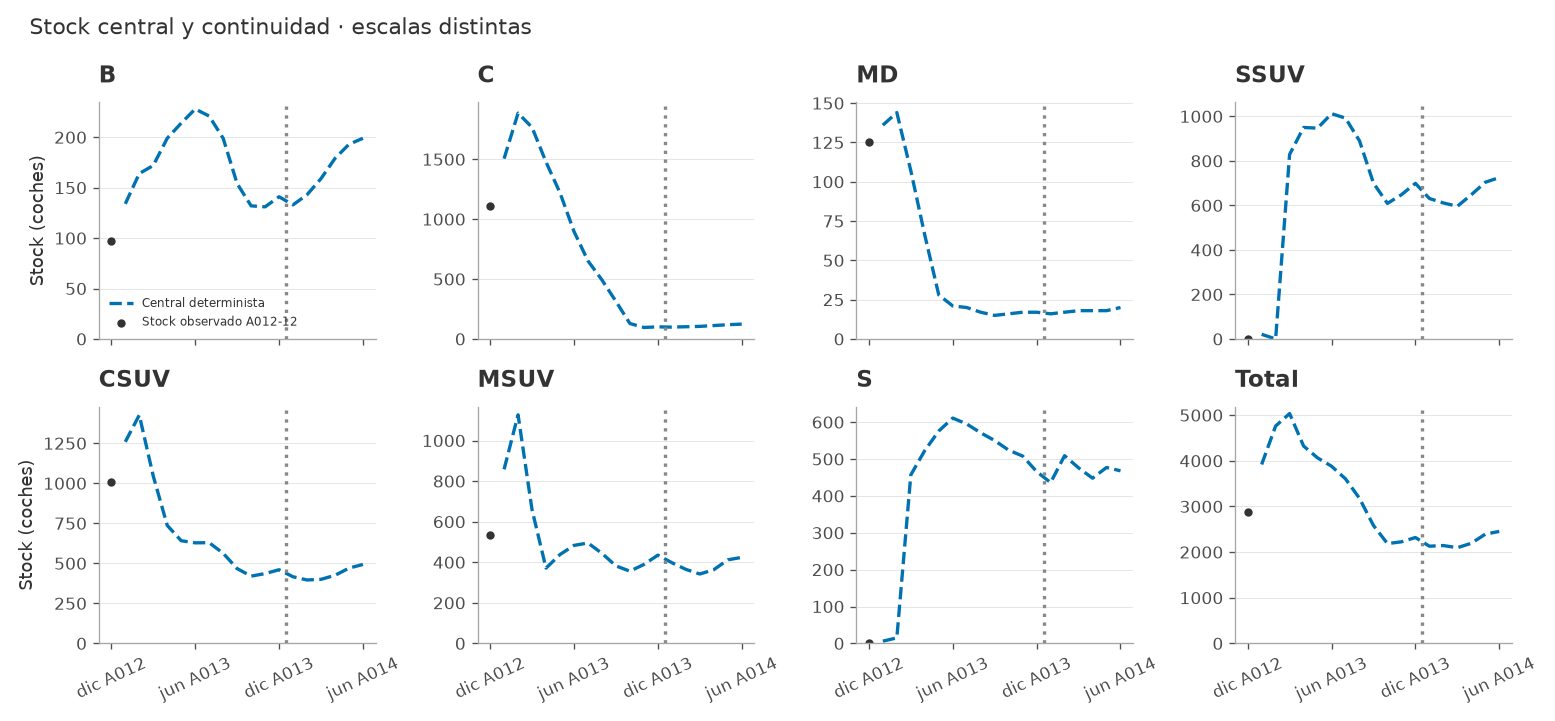

,variante,resultado_a013_eur,resultado_18_meses_eur,ventas_a013,stock_diciembre
0,Base,64181686.0,94807188.0,18991.0,2319.0
1,Pipeline últimos 3 meses,63216195.0,93841697.0,18709.0,2319.0
2,"Pipeline ×0,75",64023745.0,94649247.0,18793.0,2319.0
3,"Pipeline ×1,25",63954655.0,94580157.0,19080.0,2319.0
4,Edad inicial −15 días,64294301.0,94919803.0,18991.0,2319.0
5,Edad inicial +15 días,64075207.0,94700709.0,18991.0,2319.0
6,"VM CSUV viejo ×1,25",64181686.0,94807188.0,18991.0,2319.0


In [2]:
from pathlib import Path
from types import SimpleNamespace
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

plt.style.use("../config/graficos.mplstyle")

def cargar_api_revision(ruta):
    contenido = json.loads(Path(ruta).read_text(encoding="utf-8"))
    espacio = {"__name__": Path(ruta).stem + "_api"}
    for celda in contenido["cells"]:
        if celda["cell_type"] == "code" and "api" in celda["metadata"].get("tags", []):
            exec(compile("".join(celda["source"]), ruta, "exec"), espacio)
    return SimpleNamespace(**espacio)

api_demanda = cargar_api_revision("demanda.ipynb")
base_demanda = api_demanda.preparar_prevision_revision()
datos_sim = base_demanda["datos"]
prevision_12 = base_demanda["prevision"].reindex(columns=SEGMENTOS).to_numpy(float)
prevision_21 = extender_demanda(prevision_12, datos_sim, meses=21)
sigma3 = base_demanda["sigma3_rel"].reindex(SEGMENTOS).to_numpy(float)
assert np.isfinite(sigma3).all()
plan_base = crear_plan(prevision_21, datos_sim, sigma3)
salida_base = simular_politica(np.rint(prevision_21[:18])[None].astype(int), prevision_21,
                              datos_sim, sigma3, plan_inicial=plan_base)
mensual_base = salida_base["mensual"]
tablas = Path("../results/simulacion/tablas")
figuras = Path("../results/simulacion/figuras")
tablas.mkdir(parents=True, exist_ok=True)
figuras.mkdir(parents=True, exist_ok=True)

def periodo(m):
    return f"A{13 + m // 12:03d}{m % 12 + 1:02d}01"

filas_mensual, filas_plan, filas_pedidos = [], [], []
for m in range(18):
    for j, segmento in enumerate(SEGMENTOS):
        filas_mensual.append({"periodo": periodo(m), "segmento": segmento,
                              **{k: v[0, m, j] for k, v in mensual_base.items()}})
        filas_plan.append({"periodo_llegada": periodo(m), "periodo_decision": periodo(m-3),
                           "segmento": segmento, "llegadas": plan_base[m, j], "comprometida": m < 2})
        filas_pedidos.append({"periodo_decision": periodo(m), "periodo_llegada": periodo(m+3),
                              "segmento": segmento, "pedido": salida_base["pedidos"][0, m, j]})
mensual = pd.DataFrame(filas_mensual)
mensual.to_csv(tablas / "simulacion_central_mensual_a013_a014.csv", index=False)
mensual[mensual.periodo.str.startswith("A013")].to_csv(tablas / "simulacion_central_mensual_a013.csv", index=False)
pd.DataFrame(filas_plan).to_csv(tablas / "plan_llegadas_central_a013_a014.csv", index=False)
pd.DataFrame(filas_pedidos).to_csv(tablas / "pedidos_central_decision_a013_a014.csv", index=False)

def resumen_periodo(inicio, fin):
    acumulables = ["demanda", "ventas", "perdidas", "llegadas", "transfers", "beneficio_bruto",
                   "vm", "cvp", "coste_stock", "coste_transfer", "resultado", "intereses_concesionario"]
    resultado = pd.DataFrame({k: mensual_base[k][0, inicio:fin].sum(axis=0) for k in acumulables}, index=SEGMENTOS)
    resultado["pedidos"] = salida_base["pedidos"][0, inicio:fin].sum(axis=0)
    pesos = np.tile(DIAS_MES, 2)[inicio:fin]
    resultado["stock_medio"] = np.average(mensual_base["stock_medio"][0, inicio:fin], axis=0, weights=pesos)
    resultado["stock_fin"] = mensual_base["stock_fin"][0, fin-1]
    resultado["stock_mas_90_fin"] = mensual_base["stock_mas_90"][0, fin-1]
    resultado.loc["Total"] = resultado.sum()
    resultado["servicio"] = resultado.ventas / resultado.demanda
    resultado["cobertura_media_meses"] = resultado.stock_medio / (resultado.demanda / (fin-inicio))
    return resultado.rename_axis("segmento").reset_index()

resumen_a013 = resumen_periodo(0, 12)
resumen_a014 = resumen_periodo(12, 18)
resumen_a013.to_csv(tablas / "resumen_central_a013.csv", index=False)
resumen_a014.to_csv(tablas / "continuidad_central_enero_junio_a014.csv", index=False)
display(Markdown("### Simulación determinista central A013 · coches y euros"))
display(resumen_a013.round(2))
stock_inicial = _stock_inicial(datos_sim).sum(axis=0)
camino = plan_base[:2].sum(axis=0)
estado_inicial = pd.DataFrame({"segmento": SEGMENTOS, "stock_disponible": stock_inicial,
                               "en_camino_enero_febrero": camino,
                               "cobertura_stock_meses": stock_inicial / prevision_12.mean(axis=0),
                               "cobertura_stock_mas_camino_meses": (stock_inicial+camino) / prevision_12.mean(axis=0)})
estado_inicial.to_csv(tablas / "estado_inicial_a013.csv", index=False)
display(estado_inicial.round(2))
total = resumen_a013.iloc[-1]
display(Markdown(
    f"La referencia central determinista atiende **{total.ventas:,.0f} coches** y deja "
    f"**{total.resultado/1e6:.2f} M€** de contribución tras costes modelizados. "
    f"Termina A013 con **{total.stock_fin:,.0f} coches** en la red. "
    "Esta referencia usa z = 1,28; la política recomendada se elige después en escenarios.ipynb. "
    "Las dos coberturas tienen el mismo denominador —previsión mensual media A013—, "
    "pero solo la primera representa coches disponibles, sin tránsito."))

fig, ejes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
for j, (eje, segmento) in enumerate(zip(ejes.flat, SEGMENTOS + ["Total"])):
    valores = mensual_base["stock_fin"][0].sum(axis=1) if segmento == "Total" else mensual_base["stock_fin"][0, :, j]
    inicial = stock_inicial.sum() if segmento == "Total" else stock_inicial[j]
    eje.plot(range(1,19), valores, color="#0072B2", linestyle="--", label="Central determinista")
    eje.scatter([0], [inicial], color="#333333", s=16, label="Stock observado A012-12")
    eje.axvline(12.5, color="#888888", linestyle=":")
    eje.set_title(segmento, loc="left")
    eje.set_ylim(bottom=0)
    eje.set_xticks([0,6,12,18], ["dic A012", "jun A013", "dic A013", "jun A014"], rotation=25)
    if j % 4 == 0: eje.set_ylabel("Stock (coches)")
ejes.flat[0].legend(fontsize=7)
fig.suptitle("Stock central y continuidad · escalas distintas", x=.02, ha="left")
fig.tight_layout()
for extension in ["png", "svg"]:
    fig.savefig(figuras / f"stock_central_a013_a014.{extension}", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

filas_sensibilidad = []
for etiqueta, pipeline, mult, edad, vm_csuv in [
    ("Base", 6, 1, 0, 1), ("Pipeline últimos 3 meses", 3, 1, 0, 1),
    ("Pipeline ×0,75", 6, .75, 0, 1), ("Pipeline ×1,25", 6, 1.25, 0, 1),
    ("Edad inicial −15 días", 6, 1, -15, 1), ("Edad inicial +15 días", 6, 1, 15, 1),
    ("VM CSUV viejo ×1,25", 6, 1, 0, 1.25)]:
    plan_s = crear_plan(prevision_21, datos_sim, sigma3, meses_pipeline=pipeline, multiplicador_pipeline=mult)
    s = simular_politica(np.rint(prevision_21[:18])[None].astype(int), prevision_21, datos_sim, sigma3,
                         plan_inicial=plan_s, parametros={"edad_desplazamiento": edad, "vm_csuv_mayor_factor": vm_csuv})["mensual"]
    filas_sensibilidad.append({"variante": etiqueta, "resultado_a013_eur": s["resultado"][:, :12].sum(),
                               "resultado_18_meses_eur": s["resultado"].sum(), "ventas_a013": s["ventas"][:, :12].sum(),
                               "stock_diciembre": s["stock_fin"][0,11].sum()})
sensibilidad = pd.DataFrame(filas_sensibilidad)
sensibilidad.to_csv(tablas / "sensibilidades_pipeline_edad_vm_a013_a014.csv", index=False)
display(sensibilidad.round(2))
assert np.allclose(mensual_base["stock_inicial"] + mensual_base["llegadas"] - mensual_base["ventas_red"], mensual_base["stock_fin"])
assert np.allclose(mensual_base["demanda"], mensual_base["ventas"] + mensual_base["perdidas"])


In [3]:
# Comprobaciones locales del contrato (no requieren la API de demanda).
import pandas as pd

datos_prueba = {
    'stock': pd.read_csv('../data/stock_red_mensual.csv'),
    'segmentos': pd.read_csv('../data/catalogo_segmentos.csv'),
}
previsto_prueba = np.full((17, 7), 100.0)
plan_prueba = crear_plan(previsto_prueba, datos_prueba, np.full(7, .1))
real_prueba = np.full((2, 12, 7), 100, dtype=int)
base_prueba = simular_politica(real_prueba, previsto_prueba, datos_prueba, np.full(7, .1), plan_inicial=plan_prueba)
transfer_prueba = simular_politica(real_prueba, previsto_prueba, datos_prueba, np.full(7, .1), plan_inicial=plan_prueba, parametros={'transfer_fraccion': .5})
for salida in (base_prueba, transfer_prueba):
    mensual_prueba = salida['mensual']
    assert np.all(mensual_prueba['ventas'] == mensual_prueba['ventas_red'] + mensual_prueba['transfers'])
    assert np.all(mensual_prueba['demanda'] == mensual_prueba['ventas'] + mensual_prueba['perdidas'])
    assert np.all(mensual_prueba['stock_fin'] == mensual_prueba['stock_inicial'] + mensual_prueba['llegadas'] - mensual_prueba['ventas_red'])
    assert np.all(mensual_prueba['stock_fin'] == np.rint(mensual_prueba['stock_fin']))
assert np.array_equal(base_prueba['pedidos'][:, -1], base_prueba['llegadas_programadas'][:, 14])  # dic → mar A014
shock_prueba = simular_politica(real_prueba, previsto_prueba, datos_prueba, np.full(7, .1), plan_inicial=plan_prueba, parametros={'suministro': ('B', 2)})
assert np.array_equal(shock_prueba['llegadas_programadas'][:, :1], base_prueba['llegadas_programadas'][:, :1])
assert not shock_prueba['llegadas_programadas'][:, 4, 0].any()  # producción feb. → llegada may.
stock_cero = datos_prueba['stock'].copy()
ultimo_prueba = stock_cero['t'].max()
stock_cero.loc[stock_cero['t'] == ultimo_prueba, ['s_0_90', 's_91_180', 's_mas_180', 'stock_total']] = 0
datos_cohorte = {**datos_prueba, 'stock': stock_cero}
real_cohorte = np.zeros((1, 1, 7), dtype=int); real_cohorte[0, 0, 0] = 1
prev_cohorte = np.zeros((6, 7)); plan_cohorte = np.zeros((4, 7), dtype=int); plan_cohorte[0, 0] = 1
nuevo = simular_politica(real_cohorte, prev_cohorte, datos_cohorte, np.zeros(7), plan_inicial=plan_cohorte, parametros={'arancel_eur': [30, 0, 0, 0, 0, 0, 0]})['mensual']
assert nuevo['coste_arancel'][0, 0, 0] == 30
assert np.isclose(nuevo['stock_medio'][0, 0, 0], 15 / 31)
catalogo_freno = datos_prueba['segmentos'].copy(); catalogo_freno.loc[catalogo_freno['segmento'] == 'B', ['beneficio_bruto_marca_eur', 'vm_real_0_90_eur']] = [100, 90]
plan_freno = crear_plan(np.full((6, 7), 100.0), {**datos_cohorte, 'segmentos': catalogo_freno}, np.zeros(7), frenar_no_rentables=True)
assert plan_freno[2, 0] == 0  # contribución central 100 − 90 − 30 < 0
stock_viejo = stock_cero.copy(); mascara_b = (stock_viejo['t'] == ultimo_prueba) & (stock_viejo['segmento'] == 'B')
stock_viejo.loc[mascara_b, ['s_mas_180', 'stock_total']] = 1
viejo = simular_politica(real_cohorte, prev_cohorte, {**datos_prueba, 'stock': stock_viejo}, np.zeros(7), plan_inicial=np.zeros((4, 7), dtype=int), parametros={'arancel_eur': [30, 0, 0, 0, 0, 0, 0]})['mensual']
assert viejo['coste_arancel'][0, 0, 0] == 0
real_fifo = real_cohorte.copy(); real_fifo[0, 0, 0] = 2
plan_fifo = np.zeros((4, 7), dtype=int); plan_fifo[0, 0] = 1
fifo = simular_politica(real_fifo, prev_cohorte, {**datos_prueba, 'stock': stock_viejo}, np.zeros(7), plan_inicial=plan_fifo)['mensual']
ficha_b = datos_prueba['segmentos'].set_index('segmento').loc['B']
assert fifo['vm'][0, 0, 0] == ficha_b['vm_real_mas_180_eur'] + ficha_b['vm_real_0_90_eur']
# Interés del concesionario: integral por tramos 0–90 y 91–180 días.
assert np.isclose(nuevo['intereses_concesionario'][0, 0, 0], 15 * ficha_b['credito_dia_0_90_eur'])
def probar_interes(edad, tramo):
    stock_edad = stock_cero.copy(); mascara = (stock_edad['t'] == ultimo_prueba) & (stock_edad['segmento'] == 'B')
    stock_edad.loc[mascara, [tramo, 'stock_total']] = 1
    return simular_politica(real_cohorte, prev_cohorte, {**datos_prueba, 'stock': stock_edad}, np.zeros(7), plan_inicial=np.zeros((4, 7), dtype=int), parametros={'edad_desplazamiento': edad})['mensual']
edad85 = probar_interes(10, 's_0_90'); edad175 = probar_interes(10, 's_91_180'); edad180 = probar_interes(15, 's_91_180')
assert np.isclose(edad85['intereses_concesionario'][0, 0, 0], 5 * ficha_b['credito_dia_0_90_eur'] + 10 * ficha_b['credito_dia_91_180_eur'])
assert np.isclose(edad175['intereses_concesionario'][0, 0, 0], 5 * ficha_b['credito_dia_91_180_eur'])
assert edad180['intereses_concesionario'][0, 0, 0] == 0 and edad180['coste_stock'][0, 0, 0] == 0
real_transfer = np.zeros((1, 1, 7), dtype=int); real_transfer[0, 0, 0] = 100
transfer_directo = simular_politica(real_transfer, prev_cohorte, datos_cohorte, np.zeros(7), plan_inicial=np.zeros((4, 7), dtype=int), parametros={'transfer_fraccion': 1})['mensual']
assert transfer_directo['transfers'][0, 0, 0] == 100
assert transfer_directo['cvp'][0, 0, 0] == 100 * (ficha_b['beneficio_bruto_marca_eur'] - ficha_b['vm_real_0_90_eur'])
perdida_co2 = simular_politica(real_cohorte, prev_cohorte, datos_cohorte, np.zeros(7), plan_inicial=np.zeros((4, 7), dtype=int), parametros={'prima_co2': True, 'arancel_eur': [30, 0, 0, 0, 0, 0, 0]})['mensual']
esperado_perdido = ficha_b['beneficio_bruto_marca_eur'] - ficha_b['vm_real_0_90_eur'] - ficha_b['prima_co2_eur'] - 30
assert np.isclose(perdida_co2['cvp_perdido_neto'][0, 0, 0], esperado_perdido) and esperado_perdido < 0
h18 = simular_politica(np.full((1, 18, 7), 10, dtype=int), np.full((23, 7), 10.0), datos_prueba, np.zeros(7), plan_inicial=np.zeros((21, 7), dtype=int))
assert h18['mensual']['stock_fin'].shape == (1, 18, 7)
print('Tabla 3, frontera 180, balances, enteros y plazo diciembre–marzo correctos.')

# Tabla 3 ejercitando el planificador, no repitiendo solamente la fórmula.
stock_tabla3 = stock_cero.copy()
stock_tabla3.loc[:, "wholesale"] = 0
stock_tabla3.loc[stock_tabla3.segmento.eq("MSUV"), "wholesale"] = 700
mascara_msuv = stock_tabla3.t.eq(ultimo_prueba) & stock_tabla3.segmento.eq("MSUV")
stock_tabla3.loc[mascara_msuv, ["s_0_90", "stock_total"]] = 536
demanda_tabla3 = np.zeros((6, 7)); demanda_tabla3[:3, 5] = [550, 600, 850]
sigma_tabla3 = np.zeros(7); sigma_tabla3[5] = 100 * np.sqrt(3) / (550 + 600 + 850)
plan_tabla3 = crear_plan(demanda_tabla3, {**datos_prueba, "stock": stock_tabla3}, sigma_tabla3)
assert plan_tabla3[2, 5] == 286
assert nuevo["coste_stock"][0, 0, 0] == 30
assert viejo["coste_stock"][0, 0, 0] == 0
assert np.isclose(transfer_directo["resultado"][0, 0, 0], 100 * (ficha_b["beneficio_bruto_marca_eur"] * .8 - ficha_b["vm_real_0_90_eur"]))
assert np.array_equal(shock_prueba["pedidos"][:, :1], base_prueba["pedidos"][:, :1])
futuro_distinto = real_prueba.copy(); futuro_distinto[:, 6:] *= 3
sin_anticipacion = simular_politica(futuro_distinto, previsto_prueba, datos_prueba, np.full(7, .1), plan_inicial=plan_prueba)
assert np.array_equal(sin_anticipacion["pedidos"][:, :6], base_prueba["pedidos"][:, :6])
pd.DataFrame({"comprobacion": ["tabla_3_planificador", "coste_15_dias", "limite_180", "FIFO_VM",
                               "intereses_tramos", "transfer_VM_coste", "balance_enteros", "sin_anticipacion",
                               "pedido_diciembre_llega_marzo", "continuidad_18_meses"],
              "correcto": True}).to_csv("../results/simulacion/tablas/comprobaciones_revision.csv", index=False)
print("Comprobaciones directas del simulador correctas.")


Tabla 3, frontera 180, balances, enteros y plazo diciembre–marzo correctos.
Comprobaciones directas del simulador correctas.


## Interpretación y límites

Fuente: CSV del caso y previsión revisada; unidades enteras con pedidos redondeados hacia arriba. La demanda determinista se redondea al entero más próximo. El coste de la marca se limita a la antigüedad total de 180 días, sin reinicio en enero; los intereses de la red se informan separados. El VM ausente de CSUV viejo se aproxima con el tramo anterior y se somete a sensibilidad.

La continuación A014 conserva el nivel desestacionalizado del último trimestre y el perfil de mercado A009–A010; no repite compras adelantadas ni nuevos lanzamientos en enero. Los días mensuales siguen la convención de un año de 365 días, no un calendario real del caso. Las sensibilidades mantienen la previsión y cambian un supuesto operativo cada vez. No son probabilidades.